## YEDITEPE UNIVERSITY
## DEPARTMENT OF INDUSTRIAL ENGINEERING
# Basketball Analytics: Clustering Players by Performance Metrics
## Submitted to the Department of Industrial Engineering
## in partial fulfillment of the requirements for the course
## ISE 412: Data Science for Industrial Engineers
## Assistant Prof. Dr. Emre ÇELEBİ
## ISTANBUL, 2025

# ACKNOWLEDGEMENTS

It is with immense gratitude that we acknowledge the support and help of our Professor Emre Çelebi. Pursuing our course project under his supervision has been an experience which broadens the mind and presents an unlimited source of learning.

Finally, we would like to thank our families for their endless love and support, which makes everything more beautiful.

# 1. INTRODUCTION

Professional basketball generates vast performance data. Coaches and analysts often rely on stats like points, rebounds and assists to guide decisions. However, traditional methods may miss subtle patterns.

Clustering offers a way to group players with similar statistical profiles. By focusing on key metrics (such as points, rebounds, assists, minutes), we can uncover hidden relationships, identify role players and see which stats best separate different types of talent.

Our report uses hierarchical clustering on data for 50 NBA players from the 2023 season. The aim is to show how data analysis can deepen our understanding of player performance and improve team strategies.

# 2. PROBLEM STATEMENT

NBA teams collect many performance metrics (scuh as points, rebounds, assists, minutes) but it’s difficult to spot deeper similarities or roles by simple observation alone. This project tackles that issue by applying hierarchical clustering to find players who share similar skill profiles. Clusters can highlight each player’s strengths and roles, making it easier for coaches and managers to improve team structure and player development.

# 3. IMPORTING DATA

This project uses the nba_players_2023.csv file, which contains performance metrics for 50 NBA players during the 2023 season. Each record includes a player’s name, age, minutes per game, rebounds per game, assists per game and points per game. These variables cover a range of skills, from scoring to playmaking and defense.





The first step is to import/load the dataset using a simple read function in our code environment. After importing, a quick inspection ensures that each column is correctly labeled and that the data is intact. This involves checking the dataset’s structure and looking at the first few rows to confirm accuracy. Once satisfied with the dataset’s quality, we can proceed to clean and explore it more thoroughly.

In [ ]:
# Import/Load the dataset containing NBA player statistics
nba_data <- read.csv("nba_players_2023.csv", header = TRUE, sep = ",")

Warning message in file(file, "rt"):
“cannot open file 'nba_players_2023.csv': No such file or directory”


ERROR: Error in file(file, "rt"): cannot open the connection


In [ ]:
# Display the first few rows to check the data
head(nba_data)

,name,age,minutes_played_per_game,rebounds_per_game,assists_per_game,points_per_game
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,Admiral Schofield,25,12.2,1.7,0.8,4.2
2,Damian Lillard,32,36.3,4.8,7.3,32.2
3,Daniel Gafford,24,20.6,5.6,1.1,9.0
4,Devin Booker,26,34.6,4.5,5.5,27.8
5,Dru Smith,25,9.1,1.5,1.7,3.3
6,Eugene Omoruyi,25,11.8,2.3,0.5,4.9


In [ ]:
# Review the structure of the data
str(nba_data)

'data.frame':	50 obs. of  6 variables:
 $ name                   : chr  "Admiral Schofield" "Damian Lillard" "Daniel Gafford" "Devin Booker" ...
 $ age                    : int  25 32 24 26 25 25 28 23 32 26 ...
 $ minutes_played_per_game: num  12.2 36.3 20.6 34.6 9.1 11.8 32.1 28.9 18.9 35.9 ...
 $ rebounds_per_game      : num  1.7 4.8 5.6 4.5 1.5 2.3 11.8 4.2 3.8 6.9 ...
 $ assists_per_game       : num  0.8 7.3 1.1 5.5 1.7 0.5 5.7 3.4 1.5 3.5 ...
 $ points_per_game        : num  4.2 32.2 9 27.8 3.3 4.9 31.1 14.9 6.9 26.6 ...


In [ ]:
# Check summary statistics for each variable
summary(nba_data)

     name                age        minutes_played_per_game rebounds_per_game
 Length:50          Min.   :20.00   Min.   : 2.80           Min.   : 0.90    
 Class :character   1st Qu.:24.00   1st Qu.:16.18           1st Qu.: 3.00    
 Mode  :character   Median :25.00   Median :27.10           Median : 4.00    
                    Mean   :26.30   Mean   :24.62           Mean   : 4.55    
                    3rd Qu.:29.75   3rd Qu.:34.23           3rd Qu.: 5.05    
                    Max.   :38.00   Max.   :37.40           Max.   :11.80    
 assists_per_game points_per_game 
 Min.   : 0.100   Min.   : 1.600  
 1st Qu.: 1.200   1st Qu.: 6.125  
 Median : 1.750   Median :10.450  
 Mean   : 3.006   Mean   :14.580  
 3rd Qu.: 4.900   3rd Qu.:26.050  
 Max.   :10.200   Max.   :33.100  

# 4. DATA MANIPULATION



After confirming that our dataset is in good shape, the next step is to fine-tune it for the analysis ahead. The goal is to keep only the information we need and prepare any new metrics that might offer more insight. Here, we add a combined performance metric (Points + Rebounds + Assists) to measure a player’s all around influence on the court. We also make sure our data stays organized and clear by removing unnecessary columns and double-checking for missing values. Below is an outline of these steps along with comments on each code block.

In [ ]:
# Load libraries for data manipulation
library(dplyr)

The mutate function in dplyr allows us to add new columns. Here, we sum each player’s average points, rebounds, and assists per game into a single figure called pra_per_game. This provides a snapshot of how each player contributes across multiple stats.

In [ ]:
# Step 1: Create a combined metric for each player's total contribution
# Here, we add up points, rebounds, and assists per game into one variable called 'pra_per_game'.
nba_data <- nba_data %>%
  mutate(pra_per_game = points_per_game + rebounds_per_game + assists_per_game)

[link text](https://)In many machine learning and statistical methods, text-based columns are not directly used. Hence, we drop the name variable and keep only numeric fields (such as age, minutes_per_game and pra_per_game). Storing these in numeric_data makes it easier to standardize and cluster them later.

In [ ]:
# Step 2: Select numeric variables for later analysis
# We exclude the 'name' column because it contains text data and won't be used in calculations.
numeric_data <- nba_data %>%
  select(-name)

The colSums(is.na(nba_data)) command quickly displays if there are any empty or invalid entries in our columns. This is essential for spotting potential issues that could affect the quality of our results.

In [ ]:
# Step 3: Check for missing values in each column
# This code counts the number of NA values in each variable to ensure data completeness.
colSums(is.na(nba_data))

name                     age minutes_played_per_game 
                      0                       0                       0 
      rebounds_per_game        assists_per_game         points_per_game 
                      0                       0                       0 
           pra_per_game 
                      0

Through these steps, the data becomes focused on what matters for our clustering and remains free from obvious errors. This leads us to a cleaner dataset that is ready for the exploratory analysis and machine learning phases.

> Add blockquote



 # 5. EXPLORATORY DATA ANALYSIS

Exploratory Data Analysis (EDA) helps us understand the main patterns and relationships in the dataset before we move on to clustering. We look at how each variable is distributed, check for any strong correlations and see if certain groups of players stand out in simple plots. The aim is to reveal insights that might guide our later clustering steps.

In [ ]:
# Load libraries for data visualization and correlations
library(ggplot2)
install.packages("corrplot")
library(corrplot)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



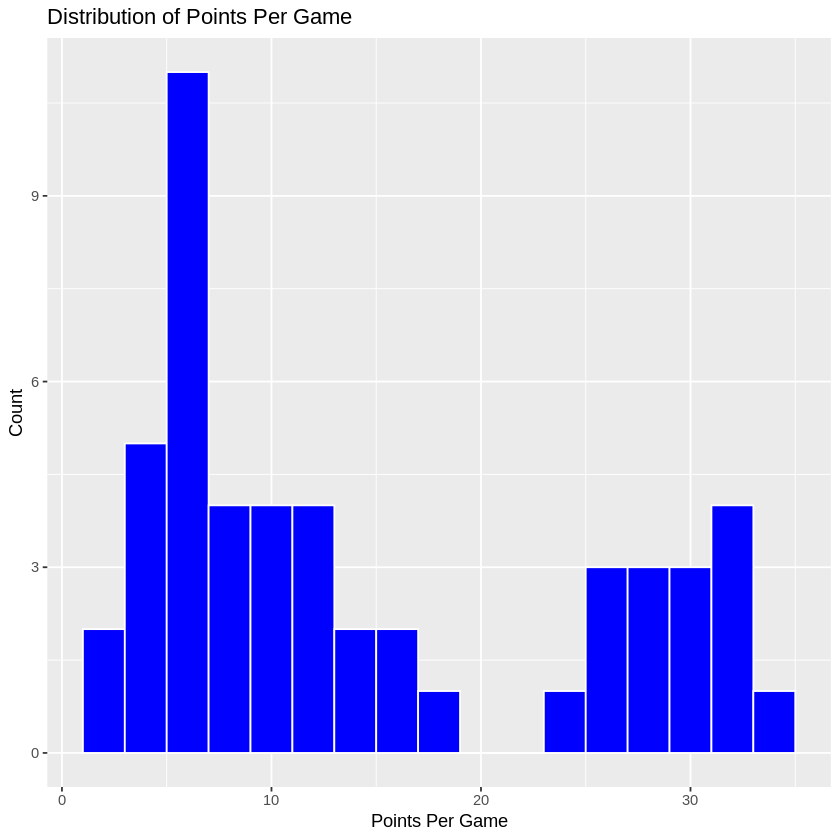

In [ ]:
# 1. Distribution of Points per Game
# A histogram to see the scoring range across players
ggplot(nba_data, aes(x = points_per_game)) +
  geom_histogram(binwidth = 2, fill = "blue", color = "white") +
  ggtitle("Distribution of Points Per Game") +
  xlab("Points Per Game") +
  ylab("Count")

1. Distribution of Points per Game:
*   This histogram shows how often certain scoring averages appear.
*   The binwidth is set to 2 so that each bar covers a small scoring range.
*   A clear peak indicates a common scoring level, while outliers may stand out on the high or low end.

In [ ]:
# 2. Frequency Table of Points Ranges
points_brackets <- cut(nba_data$points_per_game, breaks = c(0,5,10,15,20,25,30,Inf))
table(points_brackets)

points_brackets
   (0,5]   (5,10]  (10,15]  (15,20]  (20,25]  (25,30] (30,Inf] 
       7       16        9        3        1        8        6 

2.  Frequency Table of Points Ranges
*   Tables show exact counts for each bracket in points. This is useful for seeing how many players exceed 20 PPG or remain below 10 PPG.

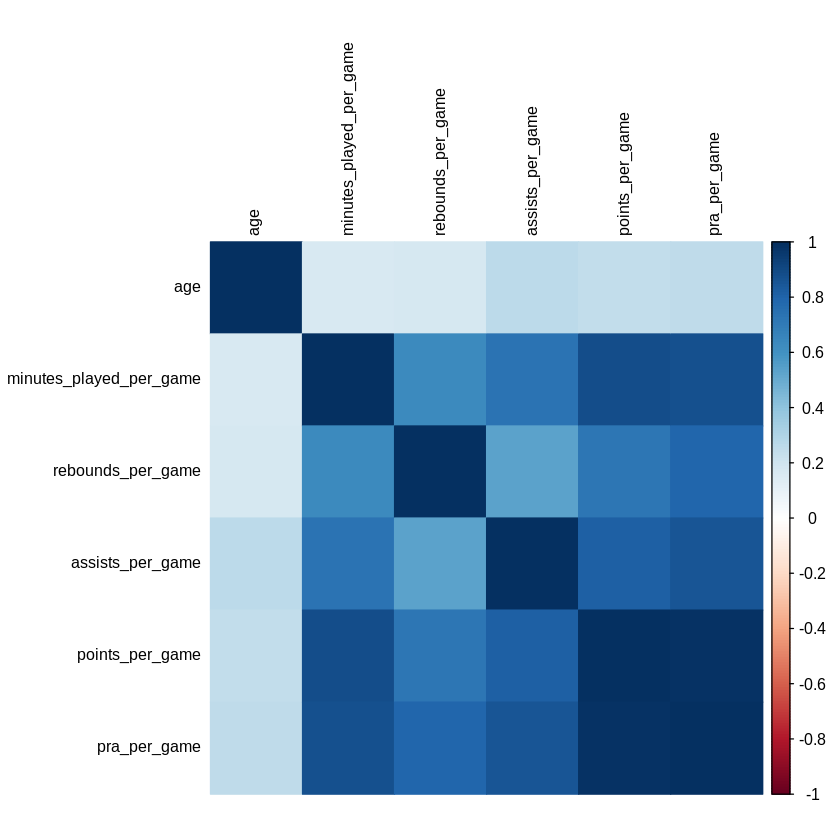

In [ ]:
# 3. Correlation Heatmap
# Create a correlation matrix of numeric variables, then plot it
numeric_data <- nba_data[, sapply(nba_data, is.numeric)]
corr_matrix <- cor(numeric_data)
corrplot(corr_matrix, method = "color", tl.col = "black", tl.cex = 0.8)

In [ ]:
summary(nba_data[, c("points_per_game", "rebounds_per_game", "assists_per_game")])

 points_per_game  rebounds_per_game assists_per_game
 Min.   : 1.600   Min.   : 0.90     Min.   : 0.100  
 1st Qu.: 6.125   1st Qu.: 3.00     1st Qu.: 1.200  
 Median :10.450   Median : 4.00     Median : 1.750  
 Mean   :14.580   Mean   : 4.55     Mean   : 3.006  
 3rd Qu.:26.050   3rd Qu.: 5.05     3rd Qu.: 4.900  
 Max.   :33.100   Max.   :11.80     Max.   :10.200  

3. Correlation Heatmap:
*   We focus only on numeric columns (numeric_data) to compute pairwise correlations.
*   A heatmap visually displays where strong positive (near +1) or strong negative (near –1) relationships might exist.
*   Observing these correlations can help us spot which metrics move together. For instance, points per game might have a strong relationship with minutes per game.

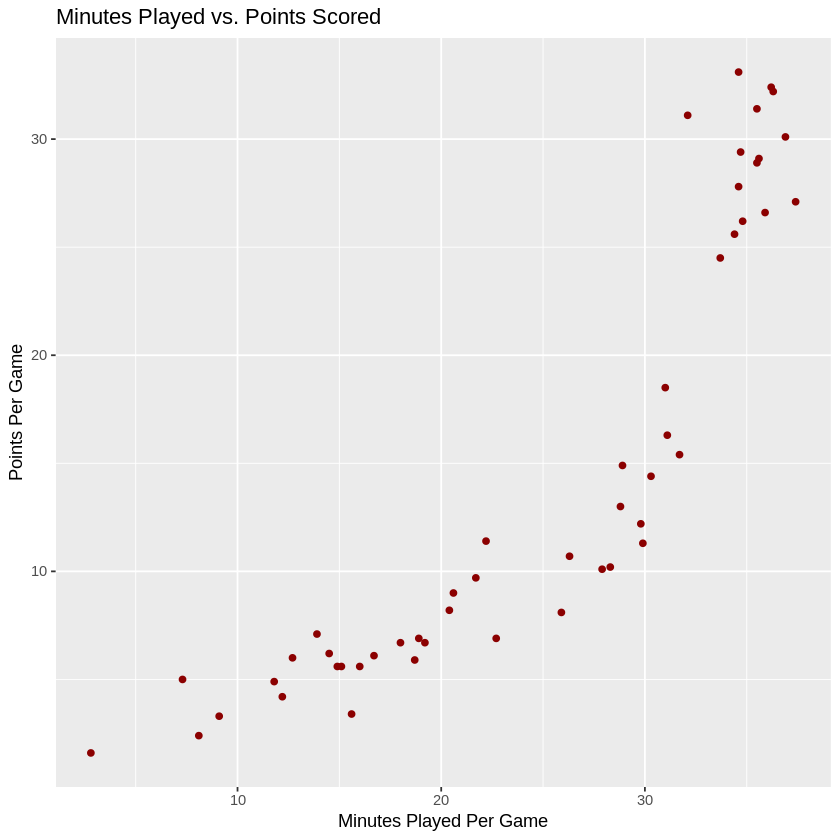

In [ ]:
# 4.  Scatter Plot of Minutes vs Points
# We often expect players with more minutes to score more, so let's check.
ggplot(nba_data, aes(x = minutes_played_per_game, y = points_per_game)) +
  geom_point(color = "darkred") +
  ggtitle("Minutes Played vs. Points Scored") +
  xlab("Minutes Played Per Game") +
  ylab("Points Per Game")

4. Scatter Plot of Minutes vs. Points:
*   This plot helps us see if players who spend more time on the court also tend to score more.
*   A visible trend can confirm that playing time is a key factor in performance outcomes.

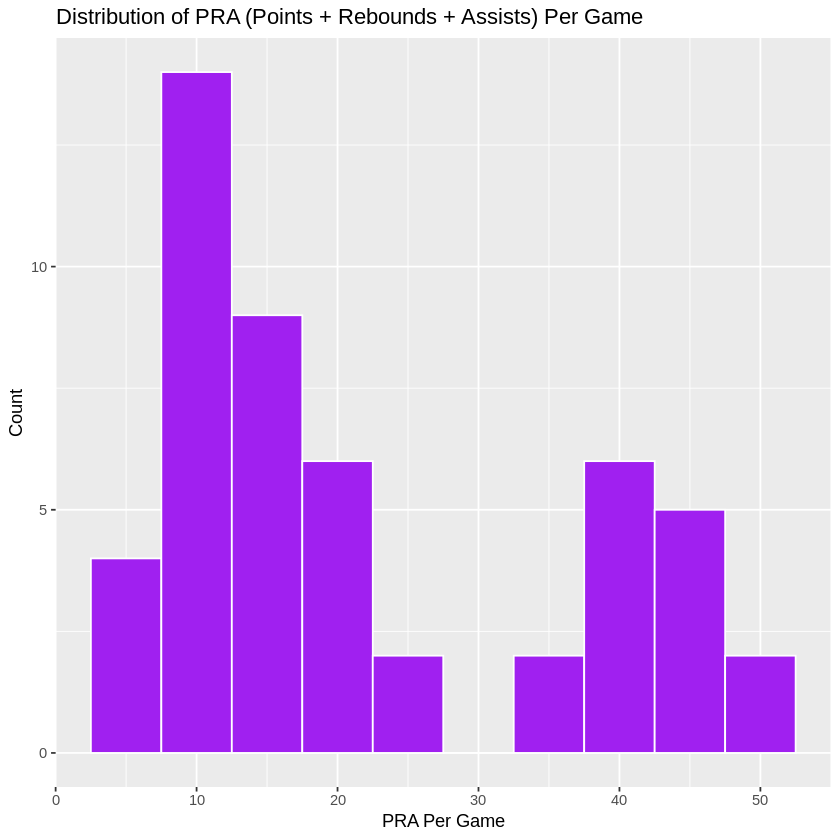

In [ ]:
# 5. Checking the new combined metric (PRA)
# This histogram shows how many players fall into each range of Points + Rebounds + Assists.
ggplot(nba_data, aes(x = pra_per_game)) +
  geom_histogram(binwidth = 5, fill = "purple", color = "white") +
  ggtitle("Distribution of PRA (Points + Rebounds + Assists) Per Game") +
  xlab("PRA Per Game") +
  ylab("Count")

5. PRA Distribution:
*   PRA (Points + Rebounds + Assists) sums up a player’s overall impact.
*   This histogram can show if most players hover around a similar range or if there are standout performers with high combined totals.

# 6. MACHINE LEARNING METHODS

Machine learning and in particular unsupervised learning, allows us to find hidden structures in data without predefined labels. In this project, we use two popular clustering algorithms: k-means and hierarchical clustering. Below, we outline each method, explain our choice and provide the code with brief explanations.

## 6.1. Data Normalization

Before clustering, it is important to normalize or scale the variables so that

---

they have a similar range. This prevents metrics with larger numeric values from dominating the clustering process.

scale() subtracts each column’s mean and divides by its standard deviation, ensuring that all variables receive equal consideration in the clustering steps.

In [ ]:
# Scale numeric data so each variable has mean = 0 and sd = 1
normalized_data <- scale(numeric_data)

In [ ]:
# Check summary of the scaled data
summary(normalized_data)

      age          minutes_played_per_game rebounds_per_game assists_per_game 
 Min.   :-1.4680   Min.   :-2.2632         Min.   :-1.4289   Min.   :-1.1477  
 1st Qu.:-0.5359   1st Qu.:-0.8762         1st Qu.:-0.6068   1st Qu.:-0.7133  
 Median :-0.3029   Median : 0.2568         Median :-0.2153   Median :-0.4961  
 Mean   : 0.0000   Mean   : 0.0000         Mean   : 0.0000   Mean   : 0.0000  
 3rd Qu.: 0.8039   3rd Qu.: 0.9956         3rd Qu.: 0.1957   3rd Qu.: 0.7480  
 Max.   : 2.7262   Max.   : 1.3249         Max.   : 2.8381   Max.   : 2.8413  
 points_per_game    pra_per_game    
 Min.   :-1.2639   Min.   :-1.3611  
 1st Qu.:-0.8233   1st Qu.:-0.8159  
 Median :-0.4022   Median :-0.3787  
 Mean   : 0.0000   Mean   : 0.0000  
 3rd Qu.: 1.1169   3rd Qu.: 1.0722  
 Max.   : 1.8034   Max.   : 1.8716  

## 6.2. K-means Clustering

K-means clustering groups observations by trying to minimize the distance between points in each cluster and its center (centroid). We use the Elbow Method to find the best number of clusters:

In [ ]:
# 1.  Compute total within-cluster sum of squares (WSS) for 1 to 10 clusters
wss <- sapply(1:10, function(k) {
  kmeans(normalized_data, centers = k, nstart = 20)$tot.withinss # Compute WSS for each k
  })

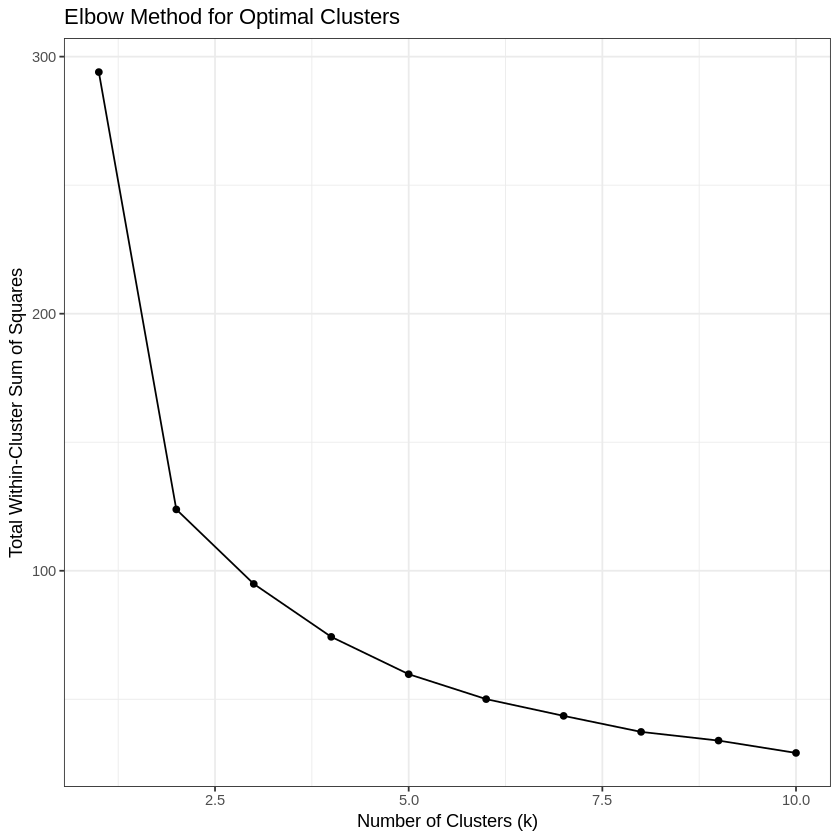

In [ ]:
# 2. Plot the Elbow Curve
# Visualize the WSS to identify the optimal number of clusters
elbow_plot <- data.frame(k = 1:10, wss = wss) %>%
  ggplot(aes(x = k, y = wss)) +
  geom_line() + # Add a line connecting points
  geom_point() + # Add points for each k value
  ggtitle("Elbow Method for Optimal Clusters") + # Title of the plot
  xlab("Number of Clusters (k)") + # Label for x-axis
  ylab("Total Within-Cluster Sum of Squares") + # Label for y-axis
  theme_bw()
elbow_plot

In [ ]:
# 3. From the Elbow Plot, decide on the number of clusters
num_clusters <- 2  # Example: we choose 2 based on the elbow point

In [ ]:
# 4. Run K-means with chosen clusters
kmeans_final <- kmeans(normalized_data, centers = num_clusters, nstart = 20)

In [ ]:
# 5. Assign cluster labels to the original data
nba_data$kmeans_cluster <- kmeans_final$cluster

table(nba_data$kmeans_cluster) shows how many players landed in each cluster (Cluster 1 vs. Cluster 2).

In [ ]:
# Distribution of players across k-means clusters
table(nba_data$kmeans_cluster) # shows how many players landed in each cluster


 1  2 
35 15 

## 6.3 Hierarchical Clustering

Hierarchical clustering gradually links individual observations into groups, forming a tree-like structure called a dendrogram. We typically look at the dendrogram to decide where to "cut" and create distinct clusters.

In [ ]:
# 1. Calculate the distance matrix using Euclidean distance
distance_matrix <- dist(normalized_data, method = "euclidean")

In [ ]:
# 2. Perform hierarchical clustering with 'average' linkage
hc_model <- hclust(distance_matrix, method = "average")

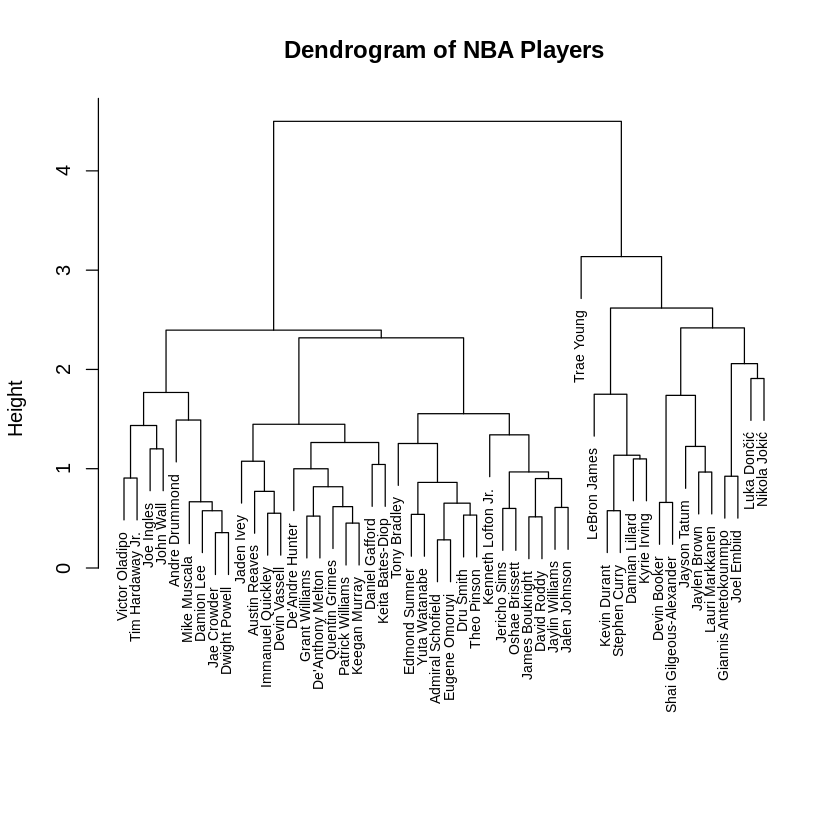

In [ ]:
# 3. Plot the dendrogram to visualize the merging process
plot(hc_model, labels = nba_data$name,
        main = "Dendrogram of NBA Players",
        xlab = "", sub = "", cex = 0.7)

In [ ]:
# 4. Choose the number of clusters based on dendrogram
hc_clusters <- cutree(hc_model, k = num_clusters)  # Same or different from K-means

In [ ]:
# 5. Store the hierarchical clusters in the dataset
nba_data$hc_cluster <- hc_clusters

In [ ]:
# Table comparing cluster assignments from both methods
table("K-means" = nba_data$kmeans_cluster,
      "Hierarchical" = nba_data$hc_cluster)

       Hierarchical
K-means  1  2
      1 35  0
      2  0 15

This cross-tab reveals if both methods agree or if there are players who appear in different clusters under the two approaches.

# 7. SUMMARY STATISTICS BY CLUSTER

After assigning each player to a cluster using both K-means and hierarchical clustering, we want to see how these clusters differ in terms of key performance indicators. By computing summary statistics (mean, standard deviation, median, min and max), we can better understand each cluster’s central tendencies and variation.

In [ ]:
# 1. Age
hc_age_stats <- nba_data %>%
  group_by(hc_cluster) %>%
  summarize(
    mean_age   = mean(age),
    sd_age     = sd(age),
    median_age = median(age),
    min_age    = min(age),
    max_age    = max(age)
  )

In [ ]:
print("Summary Statistics for Age by Hierarchical Clusters:")
hc_age_stats

[1] "Summary Statistics for Age by Hierarchical Clusters:"


hc_cluster,mean_age,sd_age,median_age,min_age,max_age
<int>,<dbl>,<dbl>,<int>,<int>,<int>
1,25.48571,3.995375,25,20,35
2,28.20000,4.491261,27,23,38


In [ ]:
# 2. Minutes Played per Game
hc_minutes_stats <- nba_data %>%
  group_by(hc_cluster) %>%
  summarize(
    mean_minutes   = mean(minutes_played_per_game),
    sd_minutes     = sd(minutes_played_per_game),
    median_minutes = median(minutes_played_per_game),
    min_minutes    = min(minutes_played_per_game),
    max_minutes    = max(minutes_played_per_game)
  )

In [ ]:
print("Summary Statistics for Minutes Played Per Game by Hierarchical Clusters:")
hc_minutes_stats

[1] "Summary Statistics for Minutes Played Per Game by Hierarchical Clusters:"


hc_cluster,mean_minutes,sd_minutes,median_minutes,min_minutes,max_minutes
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,20.08571,7.913434,19.2,2.8,31.7
2,35.21333,1.320101,35.5,32.1,37.4


In [ ]:
# 3. Rebounds per Game
hc_rebounds_stats <- nba_data %>%
  group_by(hc_cluster) %>%
  summarize(
    mean_reb   = mean(rebounds_per_game),
    sd_reb     = sd(rebounds_per_game),
    median_reb = median(rebounds_per_game),
    min_reb    = min(rebounds_per_game),
    max_reb    = max(rebounds_per_game)
  )

In [ ]:
print("Summary Statistics for Rebounds Per Game by Hierarchical Clusters:")
hc_rebounds_stats

[1] "Summary Statistics for Rebounds Per Game by Hierarchical Clusters:"


hc_cluster,mean_reb,sd_reb,median_reb,min_reb,max_reb
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,3.357143,1.243639,3.4,0.9,6.6
2,7.333333,2.687980,6.9,3.0,11.8


In [ ]:
# 4. Assists per Game
hc_assists_stats <- nba_data %>%
  group_by(hc_cluster) %>%
  summarize(
    mean_ast   = mean(assists_per_game),
    sd_ast     = sd(assists_per_game),
    median_ast = median(assists_per_game),
    min_ast    = min(assists_per_game),
    max_ast    = max(assists_per_game)
  )

In [ ]:
print("Summary Statistics for Assists Per Game by Hierarchical Clusters:")
hc_assists_stats

[1] "Summary Statistics for Assists Per Game by Hierarchical Clusters:"


hc_cluster,mean_ast,sd_ast,median_ast,min_ast,max_ast
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1.728571,1.273617,1.3,0.1,5.2
2,5.986667,2.213551,5.5,1.9,10.2


In [ ]:
# 5. Points per Game
hc_points_stats <- nba_data %>%
  group_by(kmeans_cluster) %>%
  summarize(
    mean_pts   = mean(points_per_game),
    sd_pts     = sd(points_per_game),
    median_pts = median(points_per_game),
    min_pts    = min(points_per_game),
    max_pts    = max(points_per_game)
  )

In [ ]:
print("Summary Statistics for Points Per Game by Hierarchical Clusters:")
hc_points_stats

[1] "Summary Statistics for Points Per Game by Hierarchical Clusters:"


kmeans_cluster,mean_pts,sd_pts,median_pts,min_pts,max_pts
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,8.385714,4.167814,6.9,1.6,18.5
2,29.033333,2.680796,29.1,24.5,33.1


In [ ]:
# 6. PRA (Points + Rebounds + Assists) per Game
hc_pra_stats <- nba_data %>%
  group_by(kmeans_cluster) %>%
  summarize(
    mean_pra   = mean(pra_per_game),
    sd_pra     = sd(pra_per_game),
    median_pra = median(pra_per_game),
    min_pra    = min(pra_per_game),
    max_pra    = max(pra_per_game)
  )

In [ ]:
print("Summary Statistics for PRA (Points+Rebounds+Assists) by Hierarchical Clusters:")
hc_pra_stats

[1] "Summary Statistics for PRA (Points+Rebounds+Assists) by Hierarchical Clusters:"


kmeans_cluster,mean_pra,sd_pra,median_pra,min_pra,max_pra
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,13.47143,5.642933,12.5,2.6,26
2,42.35333,4.255730,41.8,36.1,49


After computing summary statistics, certain variables show bigger average or range differences across clusters. These differences suggest which metrics (minutes_played_per_game, points_per_game and pra_per_game) drive cluster separation the most and are thus considered the “strongest influences” on how players are grouped.

In [ ]:
strongest_influence <- c(
  "minutes_played_per_game",
  "points_per_game",
  "pra_per_game"
)

By comparing K-means and hierarchical clustering results, we gain a deeper understanding of how players group together based on points, rebounds, assists, minutes played and age. This layered approach provides confidence in the final cluster structures and highlights which features matter most in separating different player types.

# 8. CONCLUSION

This project demonstrated how unsupervised learning methods, specifically k-means and hierarchical clustering, can uncover natural groupings in NBA player performance data. By carefully preparing and scaling the dataset, we minimized the chance of one variable outweighing others in shaping the clusters. Through exploratory analysis, we observed patterns in points, rebounds, assists and minutes, which guided our decisions about how many clusters to create and which metrics most influenced these groups.

The clustering results showed that players who contribute heavily in scoring and minutes tended to form distinct groups from those specializing in more modest roles. Comparing k-means and hierarchical clustering revealed that while both methods can split players in meaningful ways, their cluster assignments can differ based on how each approach merges observations.

In practical settings, coaches and analysts could use these findings to align player strengths with team strategies. Scouting departments could focus on prospects that resemble successful players in the high-performing clusters, while training staff might tailor development programs to close the gaps seen in lower-performing groups. Although we worked with a limited subset of standard statistics, the same techniques could be extended to more complex data, such as advanced analytics or player-tracking metrics.

Overall, this project underscores the value of clustering in sports analytics. Grouping players by statistical similarity creates an organized view of talent, which can improve roster construction, game planning and performance evaluation. Future research might involve adding new performance indicators, experimenting with other unsupervised algorithms or integrating dimensionality reduction methods to gain even deeper insights into player effectiveness.